# PCA, t-SNE

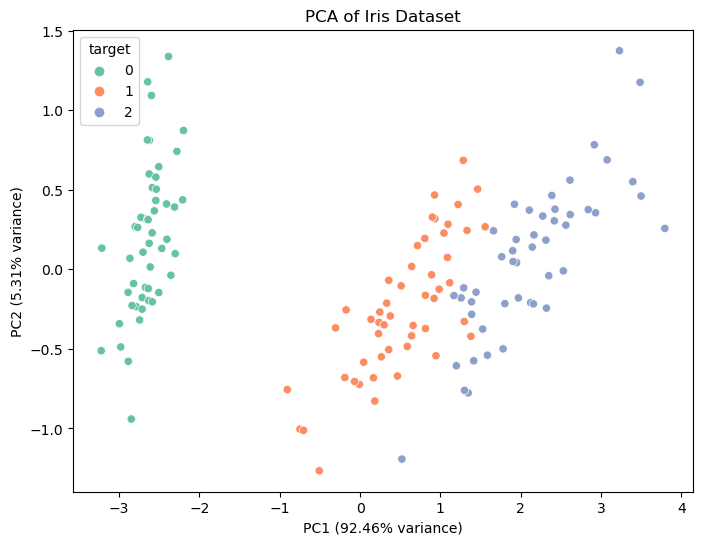

In [1]:
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create DataFrame for plotting
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['target'] = y

# Plot PCA
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="PC1", y="PC2", hue="target", 
    palette="Set2", data=df_pca,
    legend='full'
)
plt.title("PCA of Iris Dataset")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)")
plt.show()


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
# load the wine dataset
data = load_wine(as_frame=True)
X = data.data
y = data.target
labels = data.target_names[y]

In [4]:
# Standardize
X_scaled = StandardScaler().fit_transform(X)
X

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [5]:
# ____PCA_____
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    'PC1':X_pca[:,0],
    'PC2':X_pca[:,1],
    'Cultivar': labels
})

Text(0, 0.5, 'principal componenet 2')

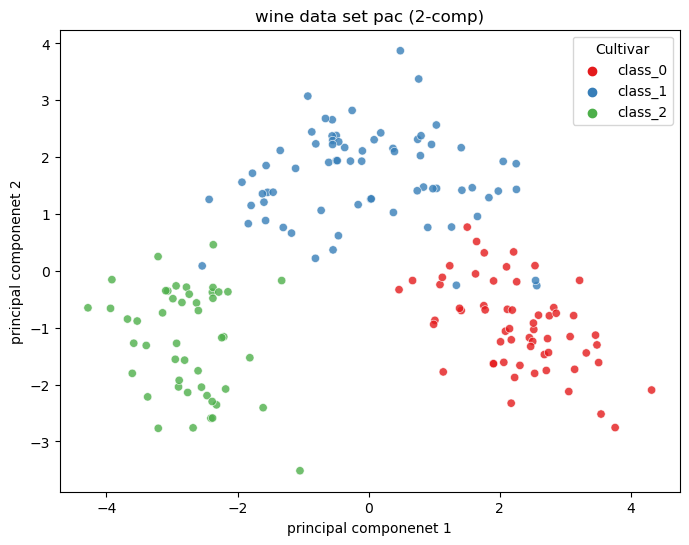

In [6]:
# plot PCA
plt.figure(figsize=(8,6))
sns.scatterplot(data = pca_df, x = 'PC1', y = 'PC2', hue = 'Cultivar',palette='Set1', alpha = 0.8)
plt.title('wine data set pac (2-comp)')
plt.xlabel('principal componenet 1')
plt.ylabel('principal componenet 2')

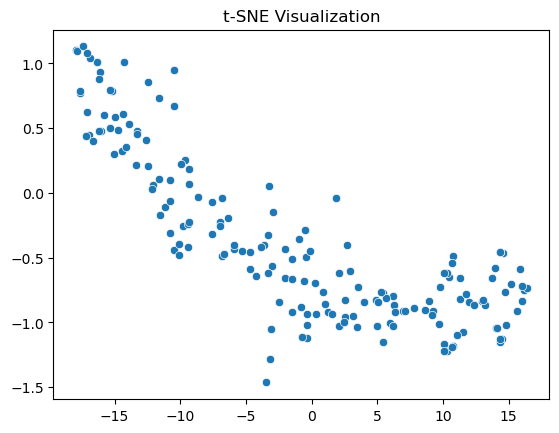

In [7]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Assume X is your high-dimensional data
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_embedded = tsne.fit_transform(X)
sns.scatterplot(x = X_embedded[:, 0], y = X_embedded[:, 1], data = X_embedded)
plt.title("t-SNE Visualization")
plt.show()

# Decision tree

 ### Machine leraning (learning from experience, data).supervoised where we have to tell computer the answer too.Unsupervoised where no target column exist

### 1-classification 2-regression

### if target value is category ML is called classification, if you have numerical value in target. ML is called regression

# Desision tree

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression

sns.set(style = 'whitegrid')

In [9]:
iris = load_iris()
df = pd.DataFrame(data =iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


C:\Users\IT_Center\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


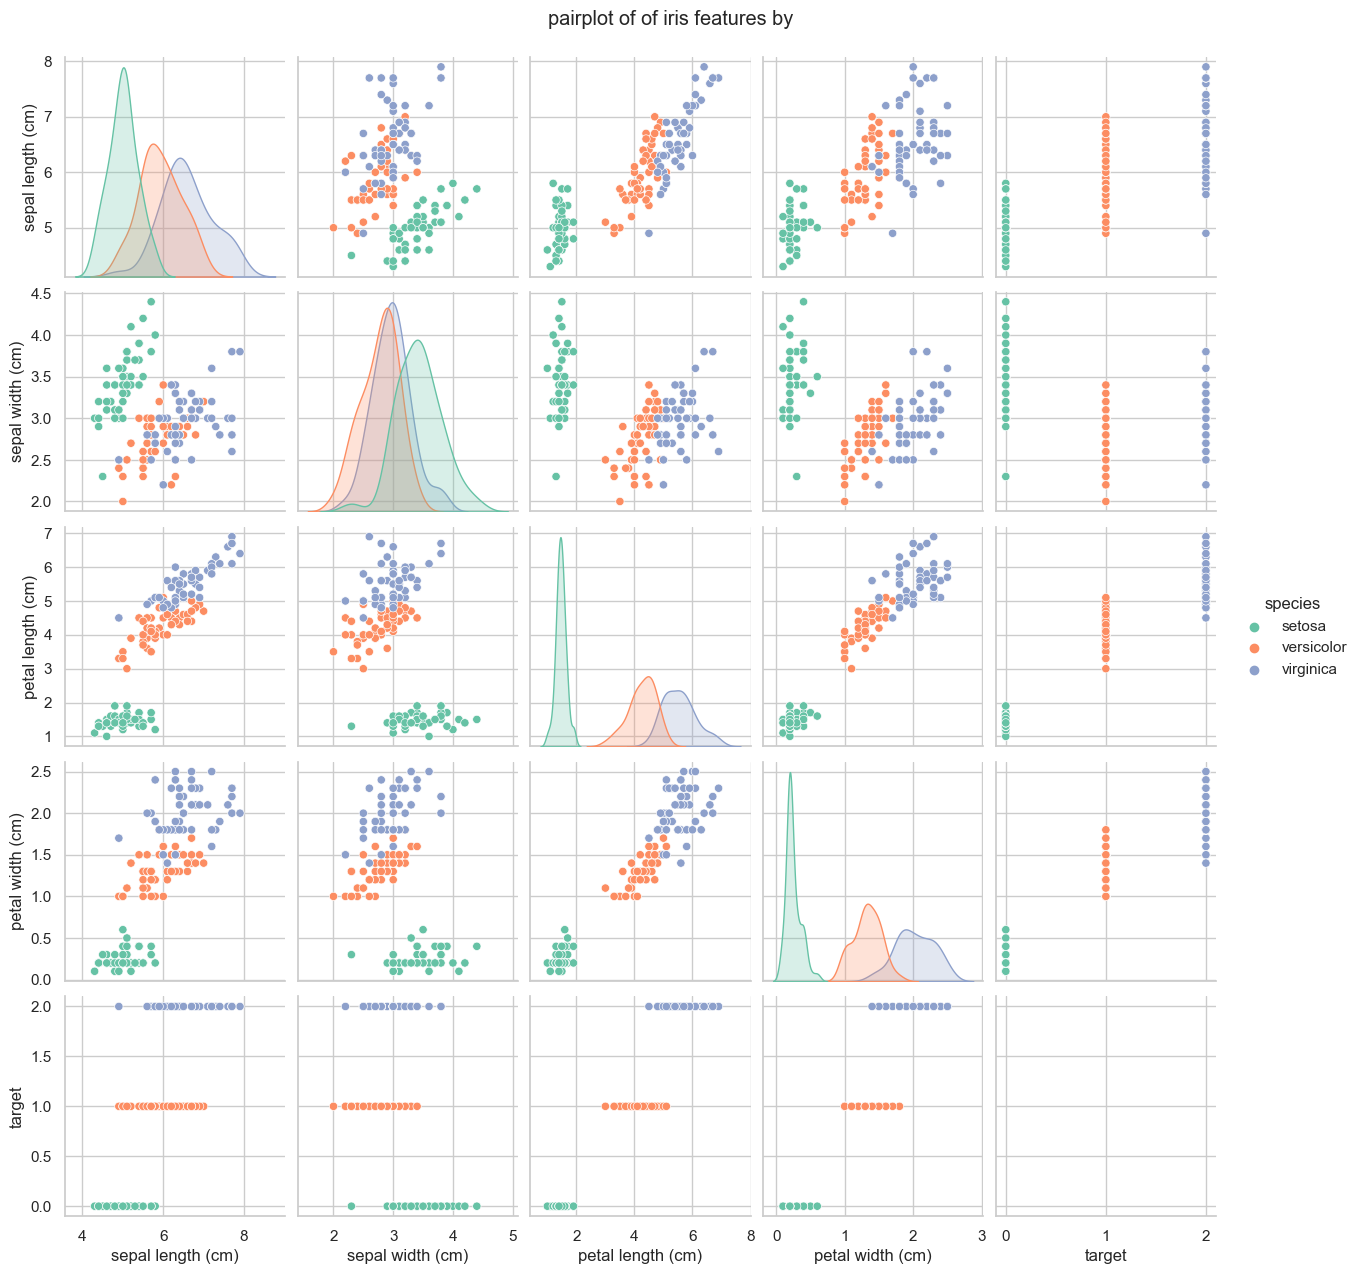

In [10]:
sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle("pairplot of of iris features by ", y=1.02)
plt.show()

In [11]:
X = df[iris.feature_names]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

# train a decision tree

Text(0.5, 1.0, 'Decision')

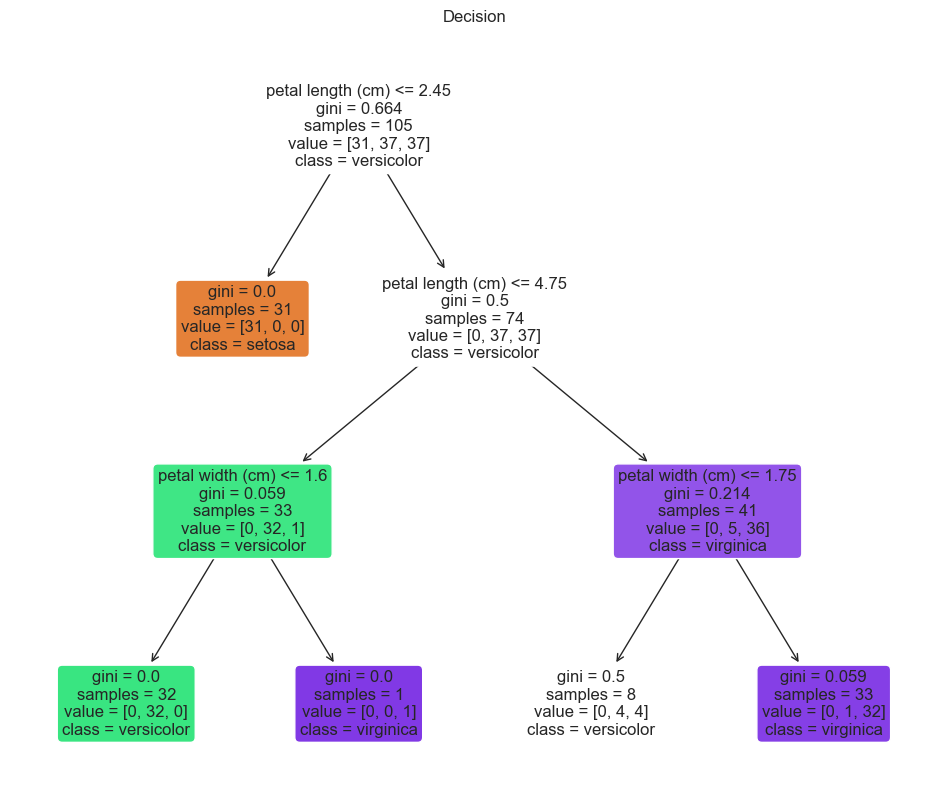

In [14]:
clf = DecisionTreeClassifier(random_state=42, max_depth=3)
clf.fit(X_train, y_train)

plt.figure(figsize=(12,10))
plot_tree(clf, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=True, rounded=True, fontsize=12)
plt.title("Decision")

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



<Axes: >

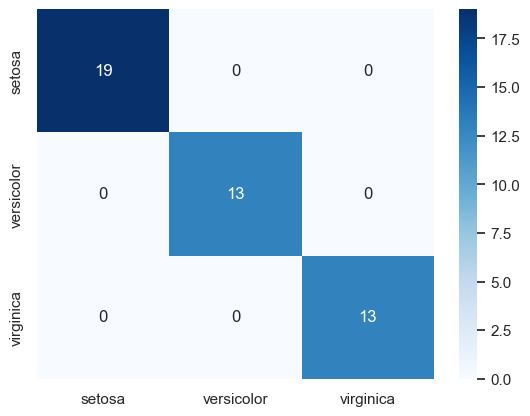

In [13]:
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap= 'Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)